In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.zip'):
            print(os.path.join(root, file))

/content/drive/MyDrive/ProjectShahd.zip
/content/drive/MyDrive/CV_Dataset.zip
/content/drive/MyDrive/CEN455/SEC_INSEC (2).zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/CV_Dataset.zip"
extract_path = "/content/CV_Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
os.listdir("/content/CV_Dataset")

['CV_Dataset']

In [ ]:
import os

dataset_path = "/content/CV_Dataset/CV_Dataset"

print(os.listdir(dataset_path))

['shuriken', 'preprocessImage.m', 'annotations', 'GUN', 'knife', 'countimages.m', 'safe']


In [ ]:
#fis+rst
import os

classes = ["GUN", "knife", "safe", "shuriken"]

for cls in classes:
    folder = os.path.join(dataset_path, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{cls}: {count}")

GUN: 801
knife: 941
safe: 111
shuriken: 92


In [ ]:
import os
import cv2
import random
import shutil

original_path = "/content/CV_Dataset/CV_Dataset"
balanced_path = "/content/CV_Dataset_Balanced"

classes = ["GUN", "knife", "safe", "shuriken"]

if os.path.exists(balanced_path):
    shutil.rmtree(balanced_path)

os.makedirs(balanced_path)

for cls in classes:
    os.makedirs(os.path.join(balanced_path, cls))

for cls in classes:
    src = os.path.join(original_path, cls)
    dst = os.path.join(balanced_path, cls)

    for file in os.listdir(src):
        if file.lower().endswith((".jpg",".jpeg",".png")):
            shutil.copy(
                os.path.join(src, file),
                os.path.join(dst, file)
            )

In [ ]:
import os
import cv2
import random

balanced_path = "/content/CV_Dataset_Balanced"

def augment_image(img):

    h, w = img.shape[:2]

    # Flip
    if random.random() > 0.5:
        img = cv2.flip(img, 1)

    # Rotation
    angle = random.uniform(-20, 20)

    M = cv2.getRotationMatrix2D(
        (w//2, h//2),
        angle,
        1.0
    )

    img = cv2.warpAffine(
        img,
        M,
        (w, h),
        borderMode=cv2.BORDER_REFLECT
    )

    # Brightness
    alpha = random.uniform(0.9, 1.1)
    beta = random.randint(-10, 10)

    img = cv2.convertScaleAbs(
        img,
        alpha=alpha,
        beta=beta
    )

    return img

target_count = 500

for cls in ["safe", "shuriken"]:

    folder = os.path.join(balanced_path, cls)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg",".jpeg",".png"))
    ]

    current_count = len(images)
    aug_id = 0

    while current_count < target_count:

        img_name = random.choice(images)

        img = cv2.imread(
            os.path.join(folder, img_name)
        )

        aug = augment_image(img)

        save_name = f"aug_{aug_id}.jpg"

        cv2.imwrite(
            os.path.join(folder, save_name),
            aug
        )

        aug_id += 1
        current_count += 1

print("Augmentation completed.")

Augmentation completed.


In [ ]:
import os

balanced_path = "/content/CV_Dataset_Balanced"

for cls in ["GUN", "knife", "safe", "shuriken"]:

    folder = os.path.join(balanced_path, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{cls}: {count}")

GUN: 801
knife: 941
safe: 500
shuriken: 500


In [ ]:
import os

dataset_path = "/content/CV_Dataset_Balanced"

label_map = {
    "safe": 0,
    "GUN": 1,
    "knife": 2,
    "shuriken": 3
}

image_paths = []
y = []

for folder, label in label_map.items():

    folder_path = os.path.join(dataset_path, folder)

    for file in os.listdir(folder_path):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(
                os.path.join(folder_path, file)
            )

            y.append(label)

print("Total images:", len(image_paths))

from collections import Counter
print(Counter(y))

Total images: 2742
Counter({2: 941, 1: 801, 0: 500, 3: 500})


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 1919
Validation: 411
Test: 412


In [ ]:
from collections import Counter

print("Train")
print(Counter(y_train))

print("\nValidation")
print(Counter(y_val))

print("\nTest")
print(Counter(y_test))

Train
Counter({2: 658, 1: 561, 3: 350, 0: 350})

Validation
Counter({2: 141, 1: 120, 3: 75, 0: 75})

Test
Counter({2: 142, 1: 120, 0: 75, 3: 75})


In [ ]:
import cv2
import numpy as np
from skimage import feature
from skimage.measure import shannon_entropy

def extract_features(image_path):

    img = cv2.imread(image_path)

    # Doctor approach
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    value = hsv[:,:,2]

    # Resize
    value = cv2.resize(value,(256,256))

    # Preprocessing
    value = cv2.GaussianBlur(value,(3,3),0)

    value = cv2.medianBlur(value,3)

    value = cv2.equalizeHist(value)

    value_float = value.astype("float32")/255.0

    # Statistical Features
    f1 = np.mean(value_float)

    f2 = np.std(value_float)

    f3 = shannon_entropy(value)

    # LBP
    lbp = feature.local_binary_pattern(
        value,
        P=24,
        R=3,
        method="uniform"
    )

    lbp_hist,_ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0,28),
        range=(0,27)
    )

    lbp_hist = lbp_hist.astype("float32")
    lbp_hist /= (lbp_hist.sum()+1e-7)

    # HOG
    hog_feat = feature.hog(
        value_float,
        orientations=12,
        pixels_per_cell=(8,8),
        cells_per_block=(2,2),
        block_norm="L2-Hys",
        visualize=False
    )

    features = np.hstack([
        f1,
        f2,
        f3,
        lbp_hist,
        hog_feat
    ])

    return features

In [ ]:
f = extract_features(X_train[0])

print("Feature Length:", len(f))
print(f[:10])

Feature Length: 46158
[0.50713277 0.29239577 6.50526608 0.03257751 0.00849915 0.0138092
 0.01644897 0.02000427 0.02255249 0.02600098]


In [ ]:
import numpy as np

print("Extracting training features...")
X_train_features = np.array([
    extract_features(p) for p in X_train
])

print("Extracting validation features...")
X_val_features = np.array([
    extract_features(p) for p in X_val
])

print("Extracting test features...")
X_test_features = np.array([
    extract_features(p) for p in X_test
])

print(X_train_features.shape)
print(X_val_features.shape)
print(X_test_features.shape)

Extracting training features...
Extracting validation features...
Extracting test features...
(1919, 46158)
(411, 46158)
(412, 46158)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_features)

X_val_scaled = scaler.transform(X_val_features)

X_test_scaled = scaler.transform(X_test_features)

print(X_train_scaled.shape)

(1919, 46158)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

knn.fit(X_train_scaled, y_train)

pred_knn = knn.predict(X_val_scaled)

acc_knn = accuracy_score(y_val, pred_knn)

print("KNN Accuracy:", acc_knn)

KNN Accuracy: 0.7372262773722628


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_scaled, y_train)

pred_rf = rf.predict(X_val_scaled)

acc_rf = accuracy_score(y_val, pred_rf)

print("RF Accuracy:", acc_rf)

RF Accuracy: 0.7274939172749392


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm = SVC(
    kernel="rbf",
    C=50,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

svm.fit(X_train_scaled, y_train)

pred_svm = svm.predict(X_val_scaled)

acc_svm = accuracy_score(y_val, pred_svm)

print("SVM Accuracy:", acc_svm)

SVM Accuracy: 0.7128953771289538


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train_scaled.shape[1])
print("PCA features:", X_train_pca.shape[1])

Original features: 46158
PCA features: 1580


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

svm_pca = SVC(
    kernel="rbf",
    C=100,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

svm_pca.fit(X_train_pca, y_train)

pred_pca = svm_pca.predict(X_val_pca)

print("PCA SVM Accuracy:", accuracy_score(y_val, pred_pca))
print("PCA SVM Macro F1:", f1_score(y_val, pred_pca, average="macro"))

PCA SVM Accuracy: 0.7347931873479319
PCA SVM Macro F1: 0.7696547852359955


In [ ]:
import joblib
import os

save_dir = "/content/drive/MyDrive/CV_Project_Model"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(svm, os.path.join(save_dir, "svm_model.pkl"))
joblib.dump(scaler, os.path.join(save_dir, "scaler.pkl"))

class_names = {
    0: "safe",
    1: "gun",
    2: "knife",
    3: "shuriken"
}

joblib.dump(class_names, os.path.join(save_dir, "class_names.pkl"))

print("Model saved successfully!")
print("Saved in:", save_dir)

Model saved successfully!
Saved in: /content/drive/MyDrive/CV_Project_Model


In [ ]:
svm = joblib.load("/content/drive/MyDrive/CV_Project_Model/svm_model.pkl")
scaler = joblib.load("/content/drive/MyDrive/CV_Project_Model/scaler.pkl")
class_names = joblib.load("/content/drive/MyDrive/CV_Project_Model/class_names.pkl")

In [ ]:
import joblib
import os

save_dir = "/content/drive/MyDrive/CV_Project_Final_Model"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(svm_pca,
            os.path.join(save_dir, "svm_pca_model.pkl"))

joblib.dump(scaler,
            os.path.join(save_dir, "scaler.pkl"))

joblib.dump(pca,
            os.path.join(save_dir, "pca.pkl"))

class_names = {
    0: "safe",
    1: "gun",
    2: "knife",
    3: "shuriken"
}

joblib.dump(class_names,
            os.path.join(save_dir, "class_names.pkl"))

print("Final model saved successfully!")

Final model saved successfully!


In [ ]:
import joblib

save_dir = "/content/drive/MyDrive/CV_Project_Final_Model"

svm_pca = joblib.load(save_dir + "/svm_pca_model.pkl")
scaler = joblib.load(save_dir + "/scaler.pkl")
pca = joblib.load(save_dir + "/pca.pkl")
class_names = joblib.load(save_dir + "/class_names.pkl")

print("Model loaded successfully")

Model loaded successfully


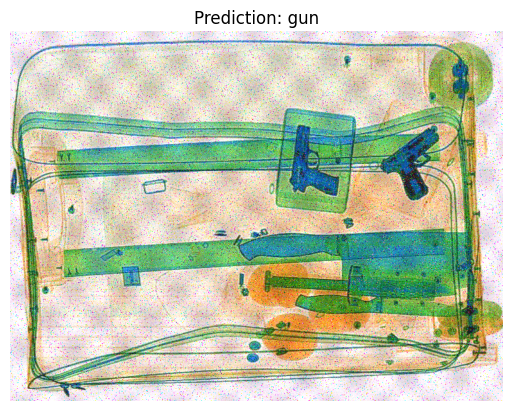

Predicted class: gun


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "/content/CV_Dataset/CV_Dataset/GUN/P00101.png"  # change this

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.title("Prediction: " + class_names[prediction])
plt.axis("off")
plt.show()

print("Predicted class:", class_names[prediction])

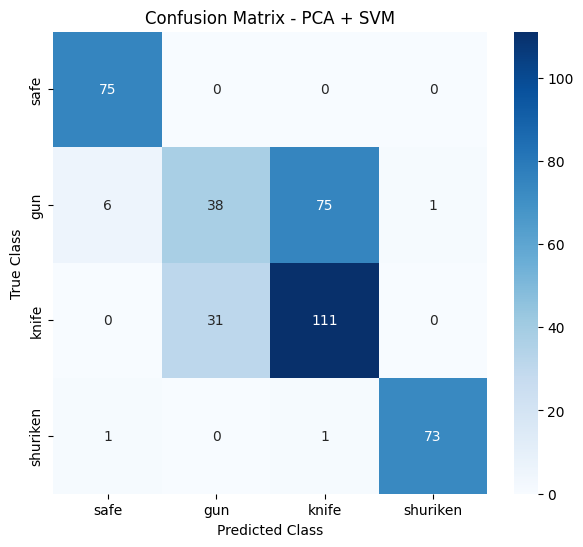

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

pred_test = svm_pca.predict(X_test_pca)

cm = confusion_matrix(y_test, pred_test)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["safe", "gun", "knife", "shuriken"],
    yticklabels=["safe", "gun", "knife", "shuriken"]
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - PCA + SVM")

plt.show()

In [ ]:
image_path = "test_image.png"

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

print(class_names[prediction])

gun


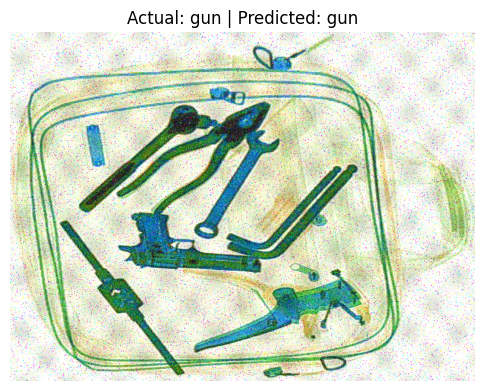

Image path: /content/CV_Dataset_Balanced/GUN/P02124.png
Actual: gun
Predicted: gun


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

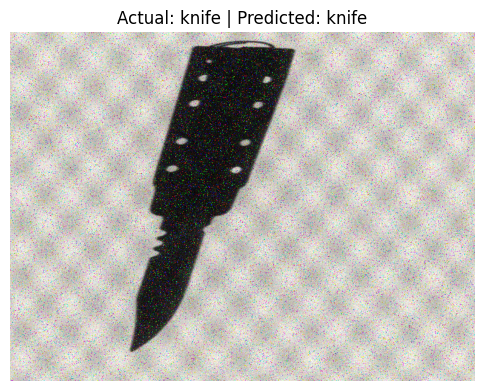

Image path: /content/CV_Dataset_Balanced/knife/B0008_0026.png
Actual: knife
Predicted: knife


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

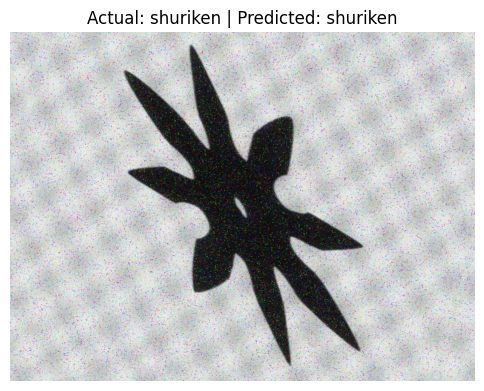

Image path: /content/CV_Dataset_Balanced/shuriken/aug_257.jpg
Actual: shuriken
Predicted: shuriken


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

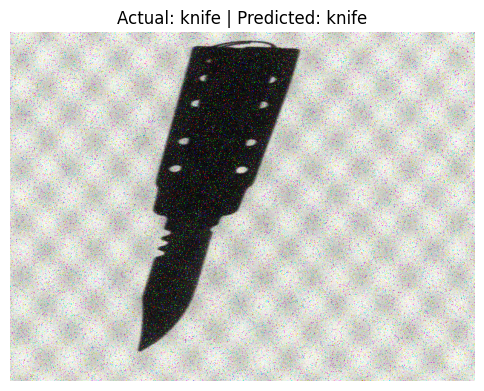

Image path: /content/CV_Dataset_Balanced/knife/B0008_0031.png
Actual: knife
Predicted: knife


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

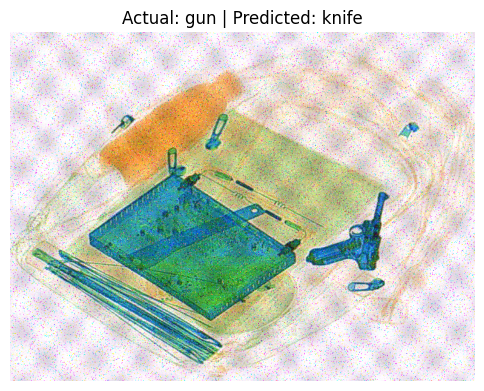

Image path: /content/CV_Dataset_Balanced/GUN/P01957.png
Actual: gun
Predicted: knife


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

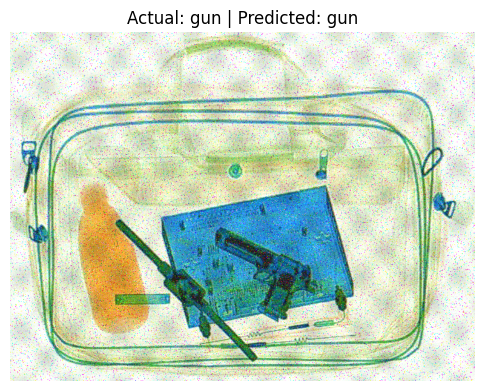

Image path: /content/CV_Dataset_Balanced/GUN/P02102.png
Actual: gun
Predicted: gun


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

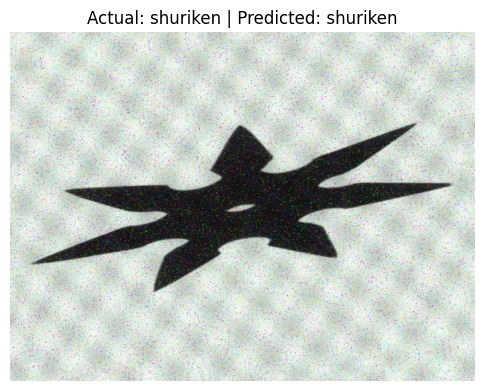

Image path: /content/CV_Dataset_Balanced/shuriken/aug_5.jpg
Actual: shuriken
Predicted: shuriken


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

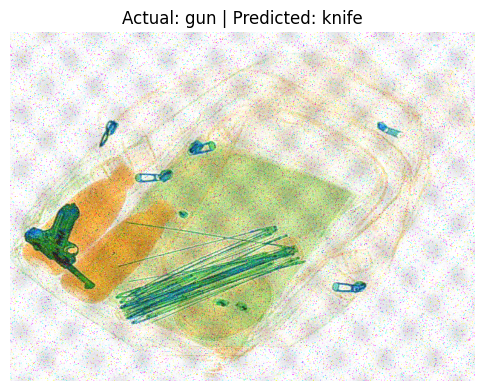

Image path: /content/CV_Dataset_Balanced/GUN/P01858.png
Actual: gun
Predicted: knife


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

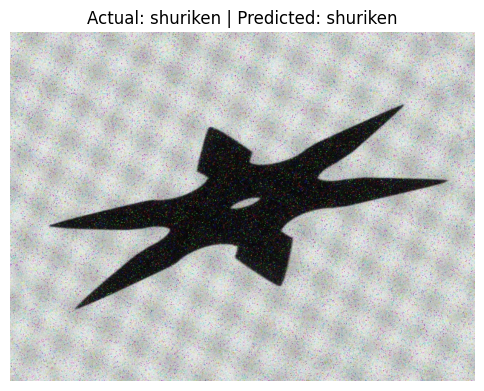

Image path: /content/CV_Dataset_Balanced/shuriken/aug_380.jpg
Actual: shuriken
Predicted: shuriken


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

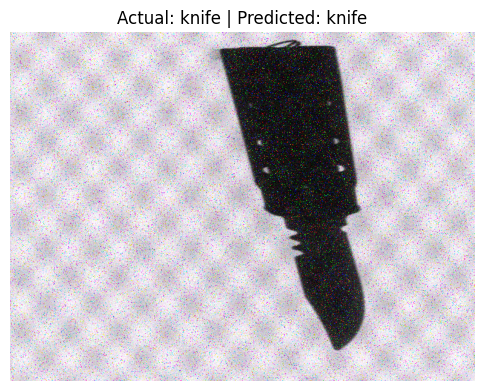

Image path: /content/CV_Dataset_Balanced/knife/B0008_0118.png
Actual: knife
Predicted: knife


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])

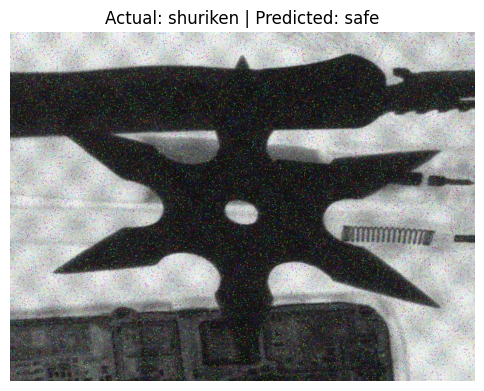

Image path: /content/CV_Dataset_Balanced/shuriken/aug_221.jpg
Actual: shuriken
Predicted: safe


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test)-1)
image_path = X_test[idx]

features = extract_features(image_path)
features_scaled = scaler.transform([features])
features_pca = pca.transform(features_scaled)

prediction = svm_pca.predict(features_pca)[0]

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(
    "Actual: " + class_names[y_test[idx]] +
    " | Predicted: " + class_names[prediction]
)
plt.axis("off")
plt.show()

print("Image path:", image_path)
print("Actual:", class_names[y_test[idx]])
print("Predicted:", class_names[prediction])